In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder 
from scipy.stats import pearsonr

In [2]:
dm_df=sns.load_dataset("diamonds")
dm_df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


داده مفقودی یافت نشد

In [3]:
dm_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


تعداد نمونه ها: 53940
تعداد رفتارها: 10

In [4]:
n_sample, n_feature = dm_df.shape
print({"feature":n_feature})
print({"n_sample":n_sample})

{'feature': 10}
{'n_sample': 53940}


داده های عددی:carat,depth,table,price,x,y,z
داده های دسته ای: cut, color, clarity 

In [5]:
dm_df.dtypes

carat       float64
cut        category
color      category
clarity    category
depth       float64
table       float64
price         int64
x           float64
y           float64
z           float64
dtype: object

In [6]:
dm_df.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [7]:
scaler=StandardScaler()

Normalizing:
Standard Scaler

In [8]:
scaled = scaler.fit_transform(dm_df[["carat", "depth", "table", "price", "x", "y","z"]])

In [9]:
dm_df["carat_scaled"]= scaled[:,0]
dm_df["depth_scaled"]= scaled[:,1]
dm_df["table_scaled"]= scaled[:,2]
dm_df["price_scaled"]= scaled[:,3]
dm_df["x_scaled"]= scaled[:,4]
dm_df["y_scaled"]= scaled[:,5]
dm_df["z_scaled"]= scaled[:,6]

Encoding Categorical Data with Map

In [10]:
dm_df["cut"].value_counts()

cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
Name: count, dtype: int64

In [11]:
dm_df["cut_id"]=dm_df["cut"].map({"Ideal" : 0,"Premium" : 1, "Very Good" : 2, "Good" : 3,"Fair": 4 })
dm_df[["cut","cut_id"]].head()

,cut,cut_id
0,Ideal,0
1,Premium,1
2,Good,3
3,Premium,1
4,Good,3


In [12]:
dm_df["color"].value_counts()

color
G    11292
E     9797
F     9542
H     8304
D     6775
I     5422
J     2808
Name: count, dtype: int64

In [13]:
encoder=LabelEncoder()
dm_df["color_id"]=encoder.fit_transform(dm_df["color"])
dm_df[["color","color_id"]].head()

,color,color_id
0,E,1
1,E,1
2,E,1
3,I,5
4,J,6


In [14]:
dm_df["clarity"].value_counts()

clarity
SI1     13065
VS2     12258
SI2      9194
VS1      8171
VVS2     5066
VVS1     3655
IF       1790
I1        741
Name: count, dtype: int64

In [15]:
encoder=LabelEncoder()
dm_df["clarity_id"]=encoder.fit_transform(dm_df["clarity"])
dm_df[["clarity","clarity_id"]].head()

,clarity,clarity_id
0,SI2,3
1,SI1,2
2,VS1,4
3,VS2,5
4,SI2,3


In [16]:
print("FEATURE RANGE")
dm_df[["carat", "depth", "table", "price"]].describe().loc[["min","max"]]

FEATURE RANGE


,carat,depth,table,price
min,0.20,43.0,43.0,326.0
max,5.01,79.0,95.0,18823.0


In [17]:
print("QUANTILE")
dm_df[["carat", "depth", "table", "price"]].describe().loc[["min","25%","50%","75%","max"]]

QUANTILE


,carat,depth,table,price
min,0.20,43.0,43.0,326.00
25%,0.40,61.0,56.0,950.00
50%,0.70,61.8,57.0,2401.00
75%,1.04,62.5,59.0,5324.25
max,5.01,79.0,95.0,18823.00


CARAT

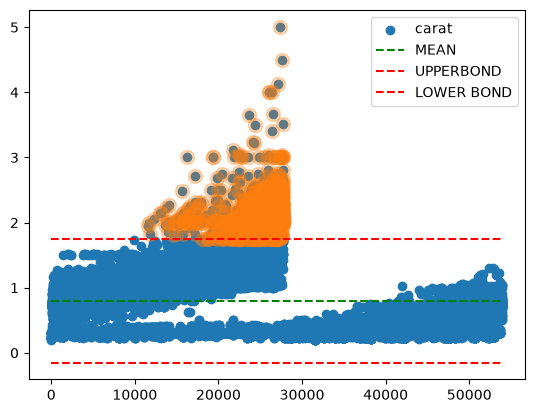

In [18]:
mean = dm_df["carat"].mean()
std = dm_df["carat"].std()

upperbond= mean + std * 2
lowerbond= mean - std * 2

outlier= dm_df[(dm_df["carat"] > upperbond) |  (dm_df["carat"] < lowerbond)]
outlier_id= dm_df.where((dm_df["carat"] > upperbond) |  (dm_df["carat"] < lowerbond))

plt.scatter(dm_df.index,dm_df["carat"],label="carat")
plt.hlines(mean,dm_df.index[0],dm_df.index[-1],color="g",linestyle="--",label="MEAN")
plt.hlines(upperbond,dm_df.index[0],dm_df.index[-1],color="r",linestyle="--",label="UPPERBOND")
plt.hlines(lowerbond,dm_df.index[0],dm_df.index[-1],color="r",linestyle="--",label="LOWER BOND")

plt.scatter(outlier.index,outlier["carat"],s=100,alpha=0.3)
plt.legend()


COVARIANCE:


In [19]:
dm_df[["carat", "depth", "table", "price", "x", "y","z"]].cov()
# "carat_scaled", "depth_scaled", "table_scaled", "price_scaled","x_scaled", "y_scaled", "z_scaled", "cut_id", "color_id", "clarity_id"

,carat,depth,table,price,x,y,z
carat,0.224687,0.019167,0.192365,1.742765e+03,0.518484,0.515248,0.318917
depth,0.019167,2.052404,-0.946840,-6.085371e+01,-0.040641,-0.048009,0.095968
table,0.192365,-0.946840,4.992948,1.133318e+03,0.489643,0.468972,0.237996
price,1742.765364,-60.853712,1133.318064,1.591563e+07,3958.021491,3943.270810,2424.712613
x,0.518484,-0.040641,0.489643,3.958021e+03,1.258347,1.248789,0.768487
y,0.515248,-0.048009,0.468972,3.943271e+03,1.248789,1.304472,0.767320
z,0.318917,0.095968,0.237996,2.424713e+03,0.768487,0.767320,0.498011


CORRELATION:

<div dir="rtl">
بیشترین همبستگی مثبت بین carat و x با مقدار 0.975 مشاهده می‌شود. همچنین carat با y و z نیز همبستگی بسیار قوی دارد. بین carat و price نیز همبستگی مثبت بسیار قوی (0.922) وجود دارد؛ بنابراین الماس‌های با وزن بیشتر معمولاً قیمت بالاتری دارند. در مقابل، depth و price تقریباً هیچ رابطه خطی با یکدیگر ندارند (−0.011).


</div>

In [20]:
dm_df[["carat", "depth", "table", "price", "x", "y","z","cut_id", "color_id", "clarity_id"]].corr()

,carat,depth,table,price,x,y,z,cut_id,color_id,clarity_id
carat,1.000000,0.028224,0.181618,0.921591,0.975094,0.951722,0.953387,0.134967,0.291437,-0.214290
depth,0.028224,1.000000,-0.295779,-0.010647,-0.025289,-0.029341,0.094924,0.218055,0.047279,-0.053080
table,0.181618,-0.295779,1.000000,0.127134,0.195344,0.183760,0.150929,0.433405,0.026465,-0.088223
price,0.921591,-0.010647,0.127134,1.000000,0.884435,0.865421,0.861249,0.053491,0.172511,-0.071535
x,0.975094,-0.025289,0.195344,0.884435,1.000000,0.974701,0.970772,0.125565,0.270287,-0.225721
y,0.951722,-0.029341,0.183760,0.865421,0.974701,1.000000,0.952006,0.121462,0.263584,-0.217616
z,0.953387,0.094924,0.150929,0.861249,0.970772,0.952006,1.000000,0.149323,0.268227,-0.224263
cut_id,0.134967,0.218055,0.433405,0.053491,0.125565,0.121462,0.149323,1.000000,0.020519,-0.122416
color_id,0.291437,0.047279,0.026465,0.172511,0.270287,0.263584,0.268227,0.020519,1.000000,-0.027795
clarity_id,-0.214290,-0.053080,-0.088223,-0.071535,-0.225721,-0.217616,-0.224263,-0.122416,-0.027795,1.000000


<Axes: >

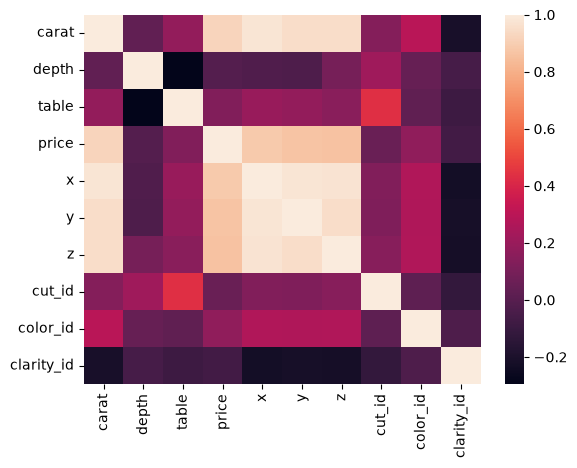

In [21]:
sns.heatmap(dm_df[["carat", "depth", "table", "price", "x", "y","z","cut_id", "color_id", "clarity_id"]].corr())

نمودار نشان می‌دهد رابطه وزن و قیمت کاملاً صعودی

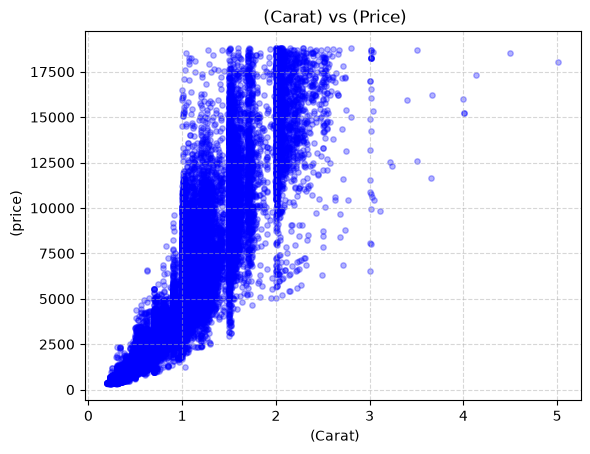

In [22]:
plt.scatter(dm_df['carat'], dm_df['price'], color='blue', alpha=0.3, s=15)

plt.title(" (Carat) vs (Price)")
plt.xlabel(' (Carat)')
plt.ylabel(' (price)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


به نظر می رسد هرچه ابعاد بزرگتر می شود قیمت هم بیشتر میشود که منطقی به نظر میرسد

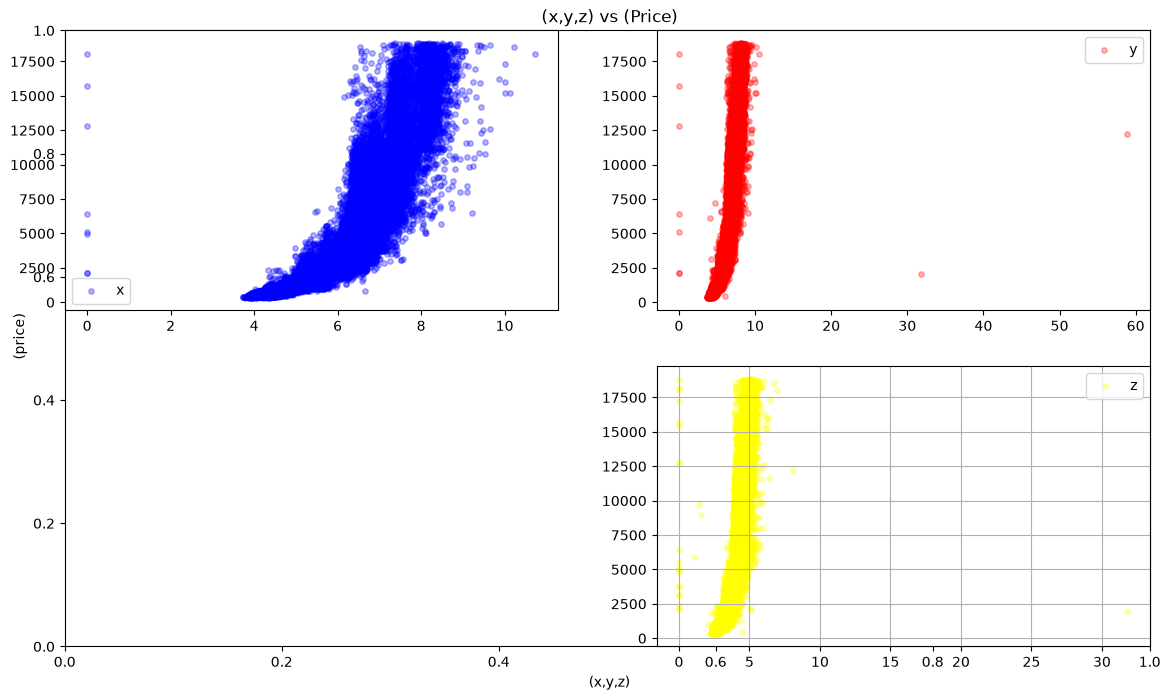

In [28]:
plt.figure(figsize=(14,8))
plt.title(" (x,y,z) vs (Price)")
plt.xlabel(' (x,y,z)')
plt.ylabel(' (price)')

plt.subplot(221)
plt.scatter(dm_df['x'], dm_df['price'], color='blue', alpha=0.3, s=15,label="x")
plt.legend()
plt.subplot(222)
plt.scatter(dm_df['y'], dm_df['price'], color='red', alpha=0.3, s=15,label="y")
plt.legend()
plt.subplot(224)
plt.scatter(dm_df['z'], dm_df['price'], color='yellow', alpha=0.3, s=15,label="z")
plt.legend()

plt.grid()
plt.show()


In [23]:
cut_counts = dm_df['cut'].value_counts()
cut_counts

cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
Name: count, dtype: int64

<div dir="rtl">
بیشترین تعداد الماس‌های موجود در دیتاست مربوط به برش باکیفیت Ideal است و برش‌های ضعیف‌تر مثل Fair کمترین سهم را به خود اختصاص داده‌اند

</div>

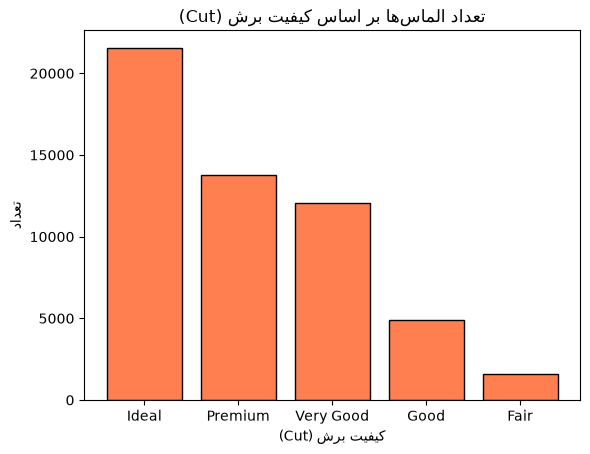

In [24]:

plt.bar(cut_counts.index, cut_counts.values, color='coral', edgecolor='black')

plt.title('تعداد الماس‌ها بر اساس کیفیت برش (Cut)')
plt.xlabel('کیفیت برش (Cut)')
plt.ylabel('تعداد')
plt.show()


<div dir="rtl">
انتظار داشتیم هرچه کیفیت برش الماس بهتر شود (مثلاً Ideal)، قیمت آن هم گران‌تر باشد؛ اما نمودار نشان می‌دهد که میانگین قیمت الماس‌های با برش ضعیف‌تر (مثل Fair و Premium) حتی از برش ایده‌آل (Ideal) بیشتر است.

</div>

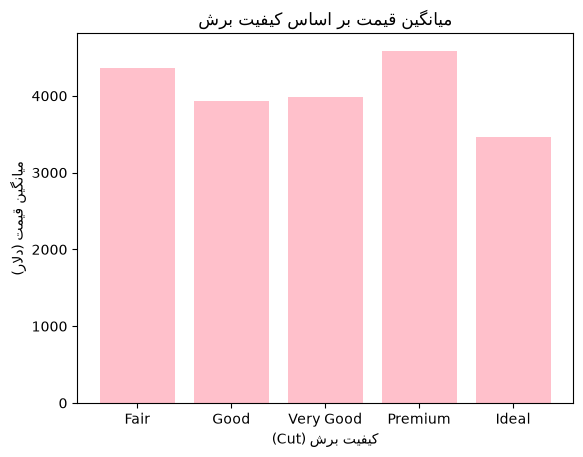

In [25]:

cuts = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
prices = [
    dm_df[dm_df["cut"] == 'Fair']['price'].mean(),
    dm_df[dm_df["cut"] == 'Good']['price'].mean(),
    dm_df[dm_df["cut"] == 'Very Good']['price'].mean(),
    dm_df[dm_df["cut"] == 'Premium']['price'].mean(),
    dm_df[dm_df["cut"] == 'Ideal']['price'].mean()
]

plt.bar(cuts, prices, color="pink", )

plt.title('میانگین قیمت بر اساس کیفیت برش')
plt.xlabel('کیفیت برش (Cut)')
plt.ylabel('میانگین قیمت (دلار)')
plt.show()


در برش ضعیف تر وزن الماس ها بالاتر است، شاید بخاطر همین موضع میانگین قیمت الماس های با برش ضعیف تر بیشتر بوده است چون وزنشان بیشتر بوده است و اگر وزن دو الماس یکی باشد، آن الماسی که برش بهتری دارد گران‌تر است

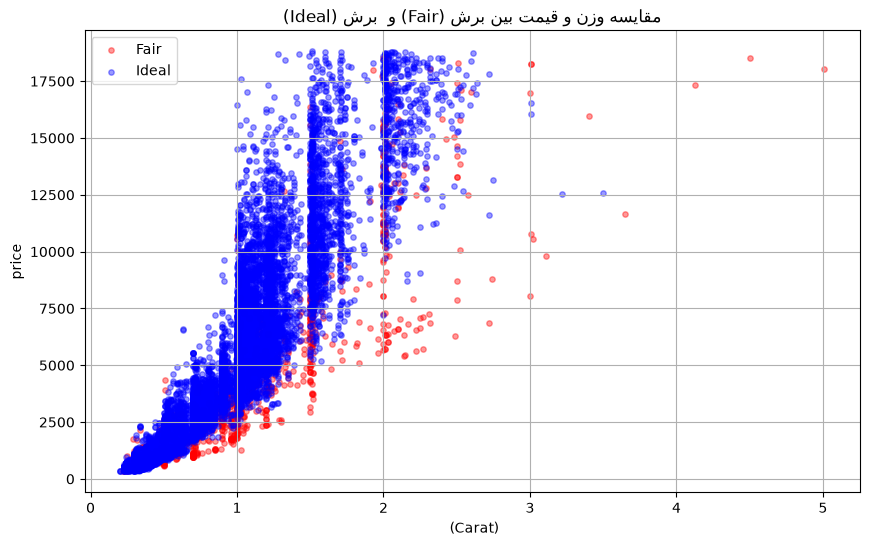

In [26]:
plt.figure(figsize=(10, 6))

# رسم هر برش با یک رنگ جداگانه روی همان نمودار
plt.scatter(dm_df[dm_df['cut'] == 'Fair']['carat'], dm_df[dm_df['cut'] == 'Fair']['price'], 
            color='red', label='Fair', alpha=0.4, s=15)

plt.scatter(dm_df[dm_df['cut'] == 'Ideal']['carat'], dm_df[dm_df['cut'] == 'Ideal']['price'], 
            color='blue', label='Ideal', alpha=0.4, s=15)

plt.title('مقایسه وزن و قیمت بین برش (Fair) و  برش (Ideal)')
plt.xlabel(' (Carat)')
plt.ylabel('price')
plt.legend()
plt.grid()
plt.show()


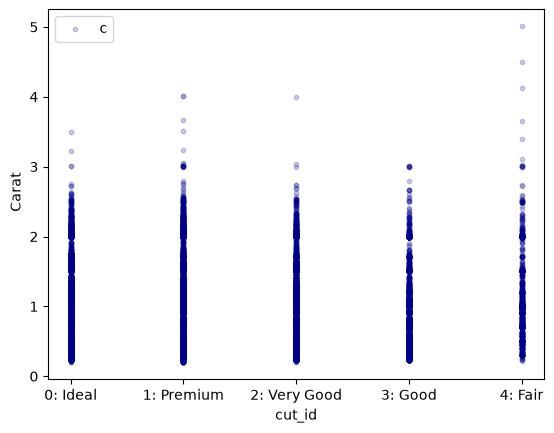

In [27]:

plt.scatter(dm_df['cut_id'], dm_df['carat'], alpha=0.2, color='darkblue', s=10)

plt.xlabel('cut_id')
plt.ylabel(' Carat')
plt.xticks(ticks=[0, 1, 2, 3, 4], 
           labels=['0: Ideal', '1: Premium', '2: Very Good', '3: Good', '4: Fair'])
plt.legend("cut_id")
plt.show()


In [79]:
print("QUANTILE")
dm_df[["carat","price_scaled"]].describe().loc[["min","25%","50%","75%","max"]]    

QUANTILE


,carat,price_scaled
min,0.20,-0.904095
25%,0.40,-0.747681
50%,0.70,-0.383967
75%,1.04,0.348787
max,5.01,3.732438


با وجود اینکه تراش سنگ بی‌نقص  و ایدآل هست قیمتش پایین تر هست ولی در نمودار سمت راست با اینکه تراش ضعیف هست ولی وزن بالاش ، قیمت را زیاد کرده است. 

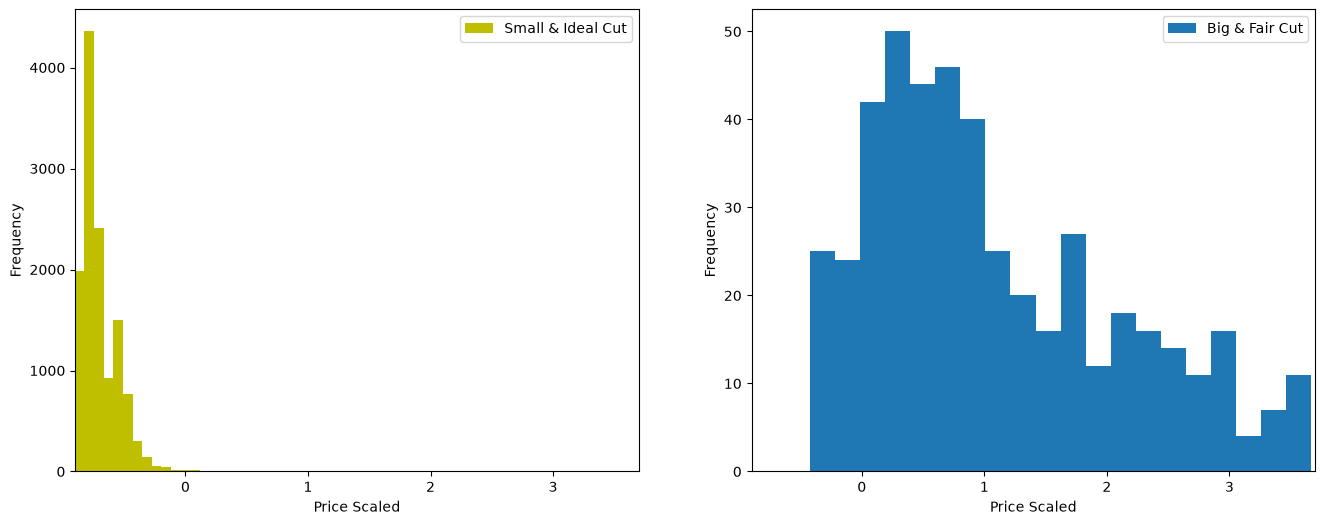

In [83]:
plt.figure(figsize=(16,6))
plt.subplot(121)
dm_df[(dm_df["carat"]< 0.7)&(dm_df["cut"]=="Ideal")]["price_scaled"].plot(kind="hist",bins=20,label="Small & Ideal Cut",color="y")
plt.xlim(-0.9, 3.7)
plt.xlabel("Price Scaled")
plt.legend()
plt.subplot(122)
dm_df[(dm_df["carat"]> 1.04)&(dm_df["cut"]=="Fair")]["price_scaled"].plot(kind="hist",bins=20,label="Big & Fair Cut")
plt.xlim(-0.9, 3.7)
plt.xlabel("Price Scaled")
plt.legend()
plt.show()